# 01. Preprocessing Comparison & Dataset Inspection

**Research Project:** *Comparative Analysis of CNN, RNN, and Hybrid CNN–RNN Architectures for Papilledema Detection and Severity Grading*

> **Notebook Role (Presentation Only):** All image loading, preprocessing metrics, quality statistics, and figure exports are implemented externally in `src/preprocessing/` and `scripts/run_preprocessing.py`, saving outputs under `results/preprocessing/`. This notebook loads verified tables and figures for inspection and interpretation.

## 1. Introduction and Objectives

This notebook evaluates the complete preprocessing pipeline transforming raw Fundus and OCT images into standardized PyTorch tensors across all four experimental tracks (`EXP-01` to `EXP-04`):

1. Verify retained and excluded sample counts after leakage/duplicate filtering.
2. Inspect raw image resolutions, aspect ratios, and disk color encodings.
3. Present real before-and-after visual comparisons across every class for Fundus, Individual OCT, OCT Sequence windows, and Exploratory OCT Severity (`G1–G4`).
4. Quantify preprocessing impact on pixel intensities, normalized tensors, RMS/Michelson contrast, Laplacian sharpness, Sobel gradient energy, and SNR proxy.
5. Preserve transparent documentation of source dataset limitations.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

PREP_DIR = Path("../results/preprocessing") if Path("../results/preprocessing").exists() else Path("results/preprocessing")
FIG_DIR = PREP_DIR / "figures"
manifest = json.loads((PREP_DIR / "preprocessing_manifest.json").read_text(encoding="utf-8"))
print(f"Analyzed: Fundus={manifest['fundus_images_analyzed']}, OCT={manifest['oct_images_analyzed']}, OCT Seq Windows (whole-df)={manifest['oct_sequence_windows_whole']}")

Analyzed: Fundus=1367, OCT=1140, OCT Seq Windows (whole-df)=146


## 2. Dataset Overview

Retained sample counts match the cleaned research manifests (`2` exact cross-class duplicates excluded from Fundus; `1` non-B-scan IR/SLO excluded from OCT; `30,000` pre-augmented OCT images and fabricated patient-ID folders strictly excluded).

In [2]:
overview_df = pd.read_csv(PREP_DIR / "dataset_overview.csv")
display(overview_df)

,track,modality,raw_retained_samples,excluded_samples,raw_color_modes,raw_width_range,raw_height_range,target_size,target_channels,use_clahe_default,normalization_mean,normalization_std
0,fundus_3class,Fundus RGB,1367,2,RGB,240-240,208-240,224x224,3,False,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]"
1,oct_individual,OCT Grayscale,1140,1,RGB,381-765,596-596,224x224,1,False,[0.5],[0.5]
2,oct_sequence,OCT Sequence (T<=8),146,11,RGB,381-765,596-596,8x1x224x224,1,False,[0.5],[0.5]
3,oct_severity,OCT Grayscale (G1-G4 exploratory),895,0,RGB,381-765,596-596,224x224,1,False,[0.5],[0.5]


## 3. Class Distribution

Notice substantial class imbalance in OCT tracks (`78.5%` Papilledema in 3-class OCT; `66.8%` G2 vs. `4.5%` G1 in exploratory severity). Original baseline models counter imbalance exclusively with inverse-frequency class-weighted Cross-Entropy Loss.

,track,class,count,pct,unit,notes
0,fundus_3class,Normal,778,56.91,image,"1,367 retained (2 cross-class duplicates exclu..."
1,fundus_3class,Papilledema,295,21.58,image,"1,367 retained (2 cross-class duplicates exclu..."
2,fundus_3class,Pseudopapilledema,294,21.51,image,"1,367 retained (2 cross-class duplicates exclu..."
3,oct_individual,Normal,132,11.58,B-scan,"1,140 retained (1 IR/SLO image excluded)"
4,oct_individual,Papilledema,895,78.51,B-scan,"1,140 retained (1 IR/SLO image excluded)"
5,oct_individual,Pseudopapilledema,113,9.91,B-scan,"1,140 retained (1 IR/SLO image excluded)"
6,oct_sequence,Normal,17,11.64,window (8-slice max),146 whole-dataset windows (147 in fixed-split ...
7,oct_sequence,Papilledema,114,78.08,window (8-slice max),146 whole-dataset windows (147 in fixed-split ...
8,oct_sequence,Pseudopapilledema,15,10.27,window (8-slice max),146 whole-dataset windows (147 in fixed-split ...
9,oct_severity,G1,40,4.47,B-scan (exploratory),Folder-derived labels only; not clinically val...


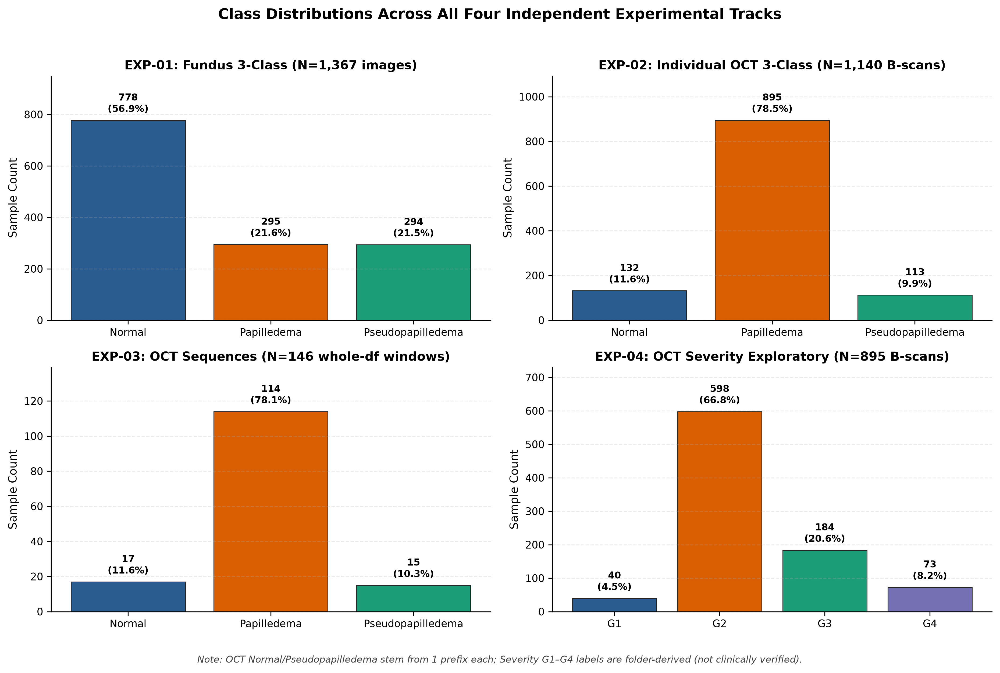

In [3]:
cls_df = pd.read_csv(PREP_DIR / "class_distribution.csv")
display(cls_df)
display(Image(filename=str(FIG_DIR / "fig01_dataset_class_distribution.png")))

## 4. Original Image Inspection

Fundus images are stored mainly at `240×240` `RGB` (two crops at `240×208` and `240×225`). Although OCT B-scans represent monochrome cross-sections, all `1,140` source files are encoded as 3-channel `RGB` at tall aspect ratios (`381×596`, `509×596`, `765×596`).

In [4]:
dim_df = pd.read_csv(PREP_DIR / "image_dimensions_summary.csv")
display(dim_df)

,dataset,raw_width,raw_height,raw_mode,count,aspect_ratio
0,fundus,240,240,RGB,1365,1.0000
1,fundus,240,208,RGB,1,1.1538
2,fundus,240,225,RGB,1,1.0667
3,oct,381,596,RGB,1062,0.6393
4,oct,509,596,RGB,76,0.8540
5,oct,765,596,RGB,2,1.2836


## 5. Preprocessing Pipeline Overview

- **Fundus (`fundus_3class`):** Cast `RGB` (`use_clahe=false` default; optional LAB-L CLAHE shown for reference) -> bilinear resize `224×224` -> ImageNet normalization (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`).
- **Individual & Severity OCT (`oct_individual`, `oct_severity`):** Cast `RGB -> L` (single-channel grayscale) -> bilinear resize `224×224` -> standardization (`mean=[0.5]`, `std=[0.5]`, range `[-1, +1]`). Training uses horizontal flip + affine/contrast jitter (**no vertical flip** to preserve retinal layer ordering).
- **OCT Sequence (`oct_sequence`):** Slices grouped by `inferred_sequence_id` into non-overlapping `T<=8` windows (`stride=8`, `min_seq_len=2`) with zero-padding masks and RNG-locked slice-consistent augmentations.

## 6. Fundus Before-and-After Comparison

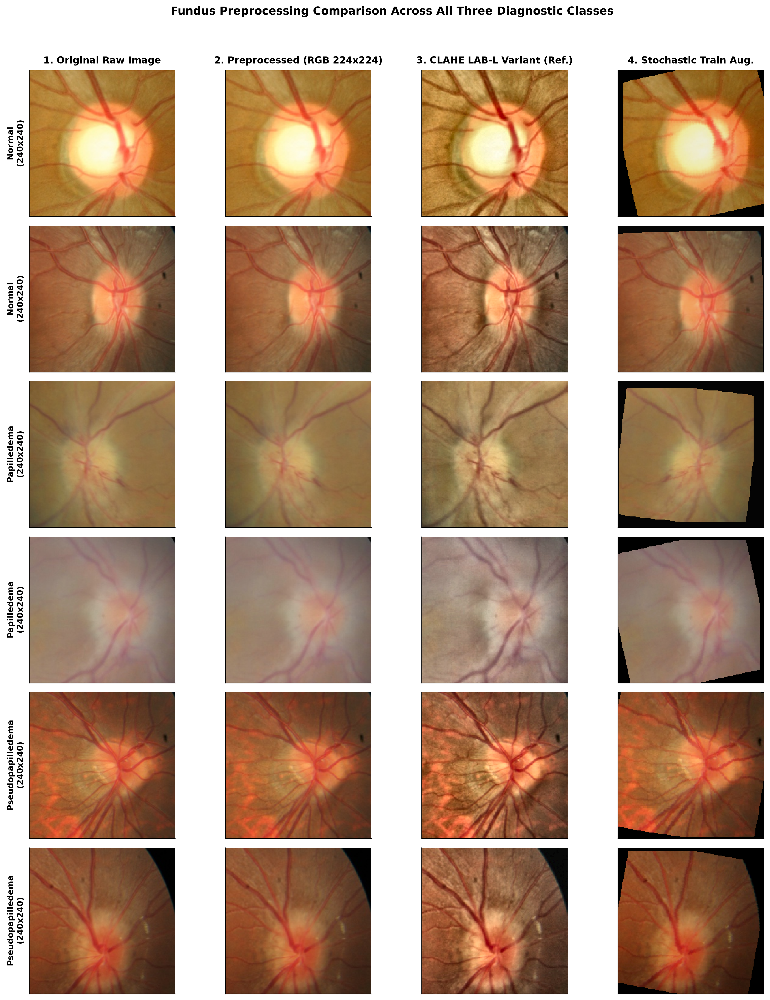

,class,stage,n_images,intensity_mean_mean,rms_contrast_mean,laplacian_var_mean,sobel_grad_mean_mean,norm_tensor_mean
0,ALL,raw,1367,119.9513,0.1104,56.4462,21.6689,NaN
1,ALL,prep,1367,119.9448,0.1101,28.9375,20.9412,-0.0527
2,ALL,clahe,1367,125.8512,0.1260,183.7311,49.4656,NaN
3,Normal,raw,778,127.5479,0.1227,62.7962,24.1964,NaN
4,Normal,prep,778,127.5407,0.1224,32.2301,23.4617,0.0725
5,Normal,clahe,778,130.8481,0.1351,200.2559,54.1640,NaN
6,Papilledema,raw,295,107.6091,0.0911,31.4262,14.5624,NaN
7,Papilledema,prep,295,107.6059,0.0909,17.4062,14.0668,-0.2865
8,Papilledema,clahe,295,118.2873,0.1088,115.1213,34.7096,NaN
9,Pseudopapilledema,raw,294,112.2329,0.0973,64.7473,22.1113,NaN


In [5]:
display(Image(filename=str(FIG_DIR / "fig02_fundus_before_after_grid.png")))
ba_df = pd.read_csv(PREP_DIR / "preprocessing_before_after_summary.csv")
display(ba_df[ba_df["track"] == "fundus_3class"][["class", "stage", "n_images", "intensity_mean_mean", "rms_contrast_mean", "laplacian_var_mean", "sobel_grad_mean_mean", "norm_tensor_mean"]].round(4))

## 7. Individual OCT Before-and-After Comparison

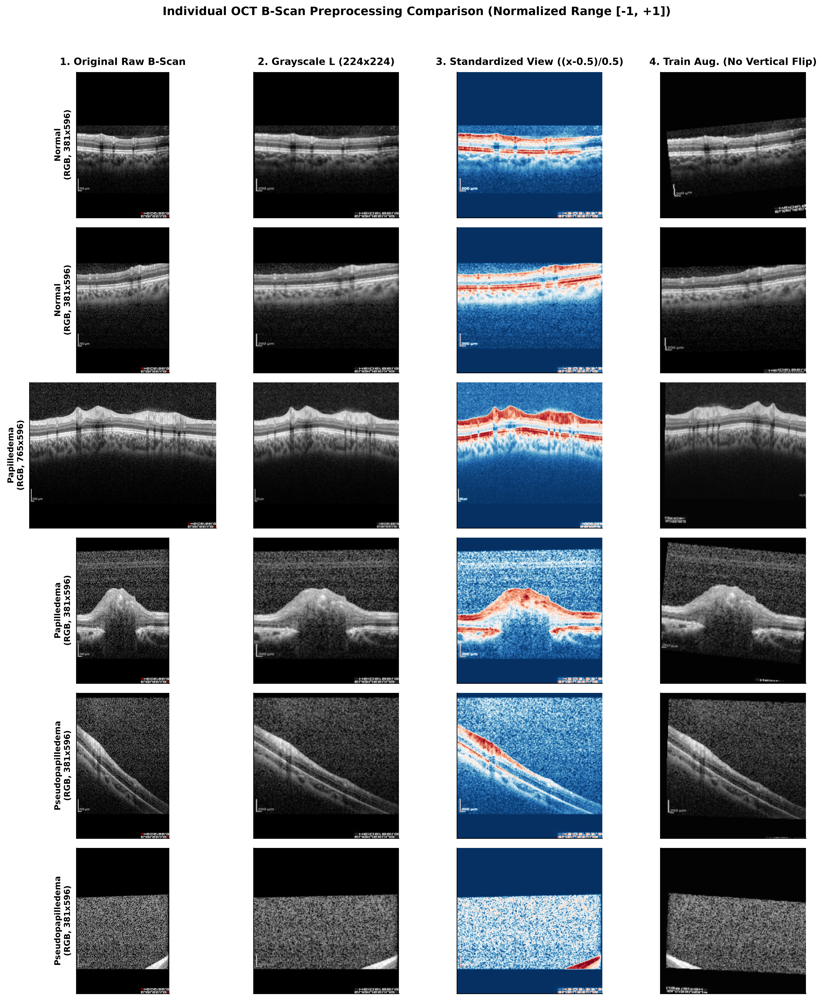

,class,stage,n_images,intensity_mean_mean,rms_contrast_mean,laplacian_var_mean,sobel_grad_mean_mean,norm_tensor_mean
12,ALL,raw,1140,47.1114,0.2210,4297.4762,105.4232,NaN
13,ALL,prep,1140,47.1233,0.2033,1986.6844,75.9293,-0.6304
14,Normal,raw,132,40.2860,0.2115,2745.4803,84.2641,NaN
15,Normal,prep,132,40.2975,0.1984,1460.5066,66.3171,-0.6839
16,Papilledema,raw,895,48.3765,0.2228,4492.9570,108.1591,NaN
17,Papilledema,prep,895,48.3885,0.2046,2047.0304,77.3347,-0.6205
18,Pseudopapilledema,raw,113,45.0644,0.2176,4562.1503,108.4715,NaN
19,Pseudopapilledema,prep,113,45.0764,0.1981,2123.3730,76.0260,-0.6465


In [6]:
display(Image(filename=str(FIG_DIR / "fig03_oct_individual_before_after_grid.png")))
display(ba_df[ba_df["track"] == "oct_individual"][["class", "stage", "n_images", "intensity_mean_mean", "rms_contrast_mean", "laplacian_var_mean", "sobel_grad_mean_mean", "norm_tensor_mean"]].round(4))

## 8. OCT Sequence Preprocessing Comparison

Whole-dataset windowing yields `146` non-overlapping windows over `1,129` slices across `21` sequences (`147` windows across `1,127` slices when evaluated post-split on the original `70/15/15` partitions). Short tail windows use explicit boolean attention masks so padded frames do not corrupt temporal pooling.

Whole-dataset sequences: 146 | Padded windows (<8 frames): 10 | Total slices used: 1129


actual_len                padded_frames                 \
                       count   mean min max         count   mean min max   
label                                                                      
Normal                    17  7.706   3   8            17  0.294   0   5   
Papilledema              114  7.763   2   8           114  0.237   0   6   
Pseudopapilledema         15  7.533   3   8            15  0.467   0   5   

                  valid_mask_ratio                     
                             count   mean    min  max  
label                                                  
Normal                          17  0.963  0.375  1.0  
Papilledema                    114  0.970  0.250  1.0  
Pseudopapilledema               15  0.942  0.375  1.0

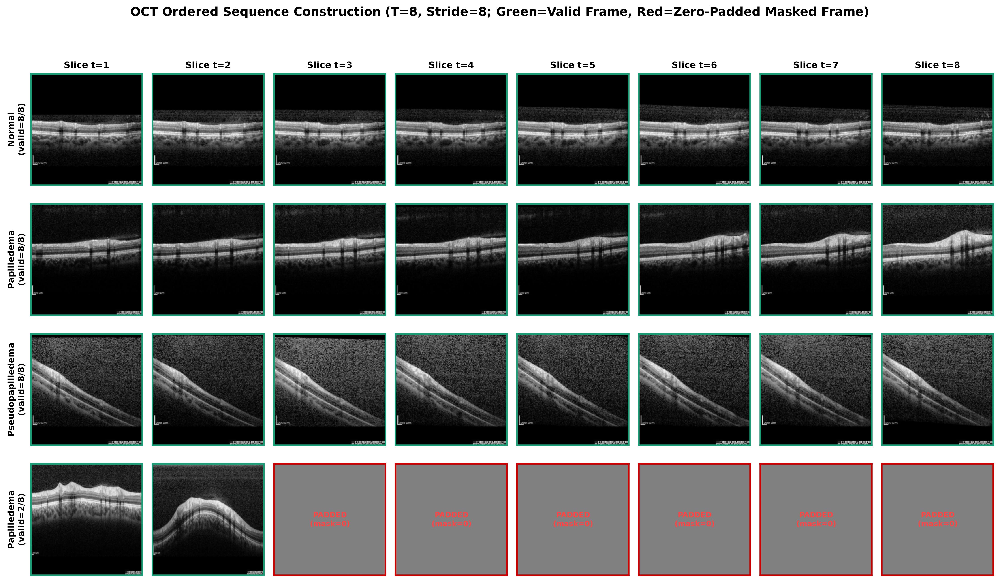

In [7]:
seq_df = pd.read_csv(PREP_DIR / "oct_sequence_preprocessing_summary.csv")
print(f"Whole-dataset sequences: {len(seq_df)} | Padded windows (<8 frames): {int((seq_df['actual_len'] < 8).sum())} | Total slices used: {int(seq_df['actual_len'].sum())}")
display(seq_df.groupby("label")[["actual_len", "padded_frames", "valid_mask_ratio"]].agg(["count", "mean", "min", "max"]).round(3))
display(Image(filename=str(FIG_DIR / "fig04_oct_sequence_preprocessing_grid.png")))

## 9. Severity Dataset Preprocessing Comparison

Representative `G1–G4` OCT B-scans before and after `224×224` grayscale standardization. *Caveat:* `G1–G4` labels are derived from source folder names rather than clinical Frisén grading.

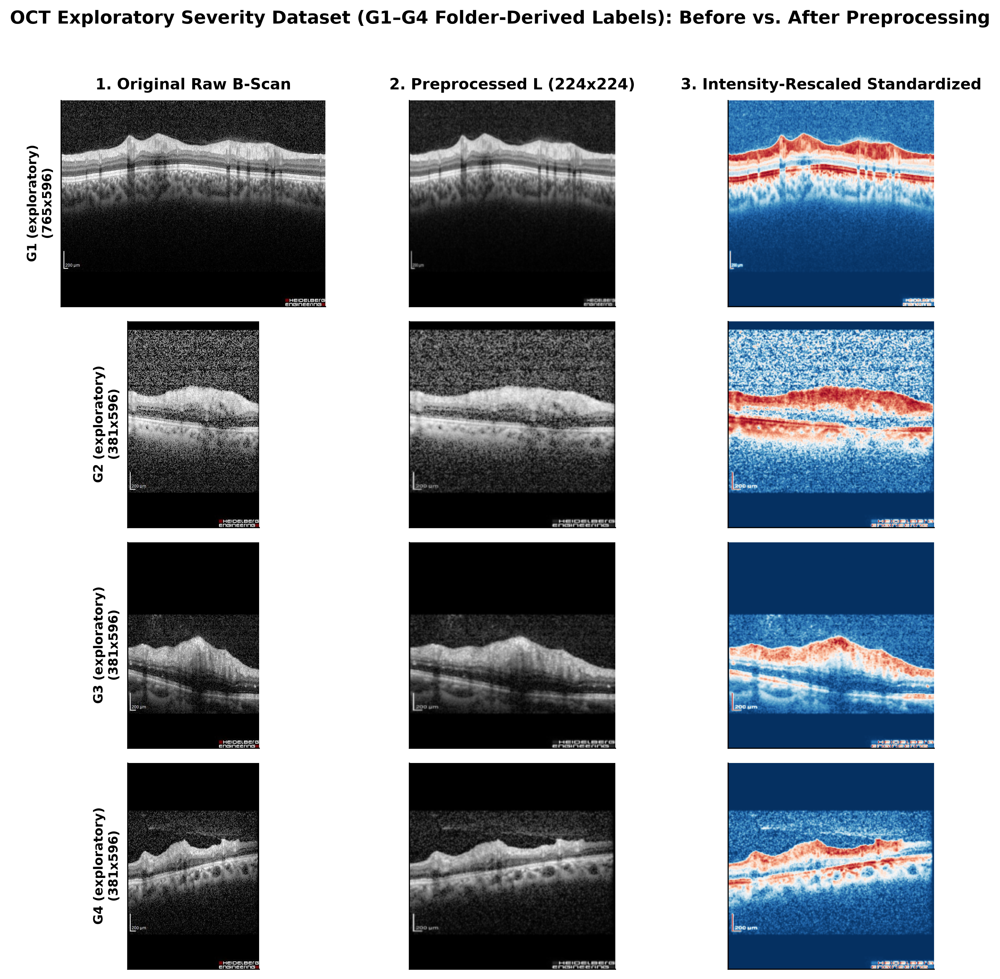

,class,stage,n_images,intensity_mean_mean,rms_contrast_mean,laplacian_var_mean,sobel_grad_mean_mean
20,ALL,raw,895,48.3765,0.2228,4492.9570,108.1591
21,ALL,prep,895,48.3885,0.2046,2047.0304,77.3347
22,G1,raw,40,40.0424,0.2130,3750.9321,88.7303
23,G1,prep,40,40.0556,0.1974,1179.1211,61.4597
24,G2,raw,598,50.4429,0.2265,4455.7474,110.5224
25,G2,prep,598,50.4549,0.2084,2099.5825,79.5437
26,G3,raw,184,45.8307,0.2182,5240.5228,109.6265
27,G3,prep,184,45.8425,0.1981,2206.1145,76.0995
28,G4,raw,73,42.4324,0.2096,3320.0828,95.7462
29,G4,prep,73,42.4440,0.1940,1691.1225,71.0514


In [8]:
display(Image(filename=str(FIG_DIR / "fig05_oct_severity_before_after_grid.png")))
display(ba_df[ba_df["track"] == "oct_severity"][["class", "stage", "n_images", "intensity_mean_mean", "rms_contrast_mean", "laplacian_var_mean", "sobel_grad_mean_mean"]].round(4))

## 10. Image Dimension Analysis

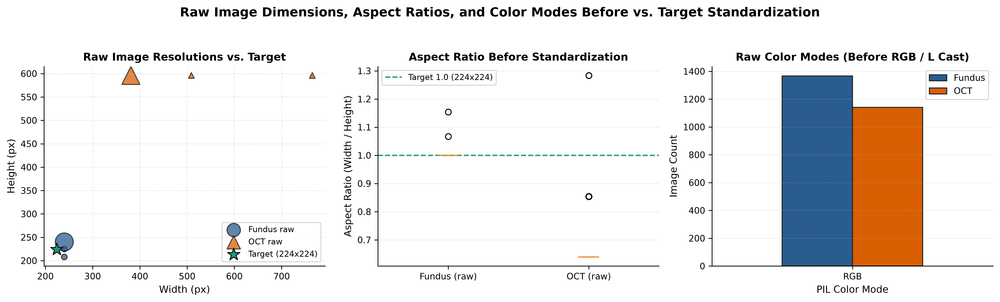

In [9]:
display(Image(filename=str(FIG_DIR / "fig06_image_resolution_analysis.png")))

## 11. Pixel Intensity Distributions

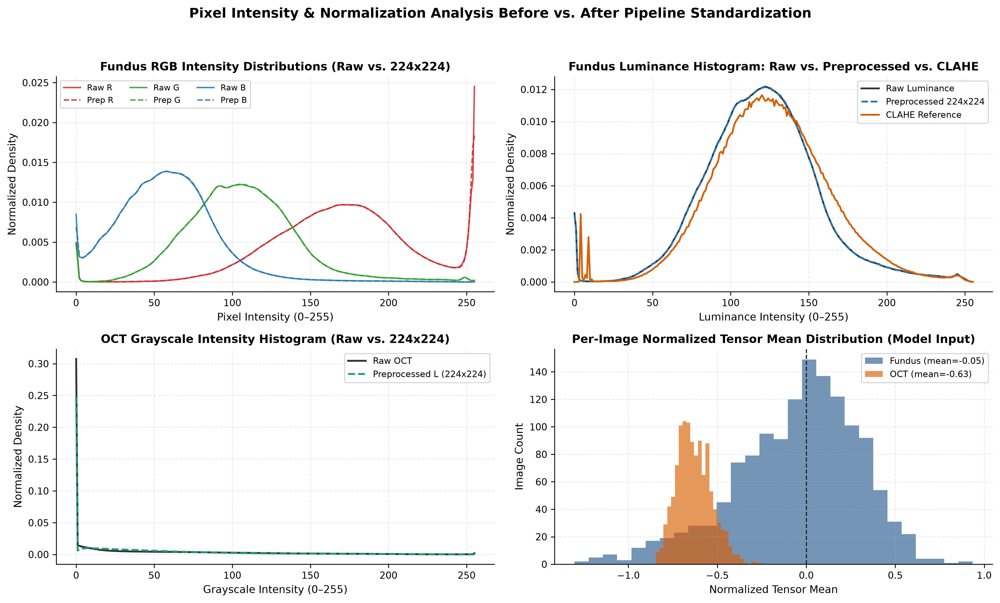

In [10]:
display(Image(filename=str(FIG_DIR / "fig07_pixel_intensity_distributions.png")))

## 12. Contrast Analysis

In [11]:
f_img = pd.read_csv(PREP_DIR / "per_image_metrics_fundus.csv")
o_img = pd.read_csv(PREP_DIR / "per_image_metrics_oct.csv")
contrast_tbl = pd.DataFrame([
    {"Stage": "Fundus Raw", "RMS Contrast": f_img["raw_rms_contrast"].mean(), "Michelson Contrast": f_img["raw_michelson_contrast"].mean()},
    {"Stage": "Fundus Preprocessed (224x224 RGB)", "RMS Contrast": f_img["prep_rms_contrast"].mean(), "Michelson Contrast": f_img["prep_michelson_contrast"].mean()},
    {"Stage": "Fundus CLAHE (Reference Only)", "RMS Contrast": f_img["clahe_rms_contrast"].mean(), "Michelson Contrast": f_img["clahe_michelson_contrast"].mean()},
    {"Stage": "OCT Raw", "RMS Contrast": o_img["raw_rms_contrast"].mean(), "Michelson Contrast": o_img["raw_michelson_contrast"].mean()},
    {"Stage": "OCT Preprocessed (224x224 L)", "RMS Contrast": o_img["prep_rms_contrast"].mean(), "Michelson Contrast": o_img["prep_michelson_contrast"].mean()},
])
display(contrast_tbl.round(4))

,Stage,RMS Contrast,Michelson Contrast
0,Fundus Raw,0.1104,0.7210
1,Fundus Preprocessed (224x224 RGB),0.1101,0.7130
2,Fundus CLAHE (Reference Only),0.1260,0.7826
3,OCT Raw,0.2210,1.0000
4,OCT Preprocessed (224x224 L),0.2033,1.0000


## 13. Image Quality Analysis

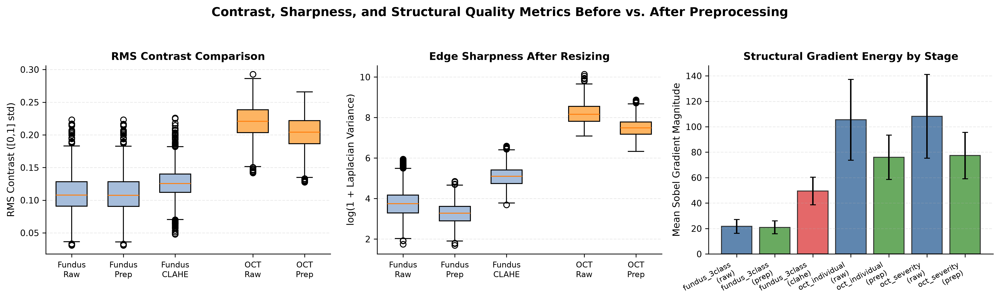

In [12]:
display(Image(filename=str(FIG_DIR / "fig08_contrast_and_quality_analysis.png")))

## 14. Summary and Observations

1. **Standardization Preserves Global Intensity:** Bilinear resizing (`240×240 -> 224×224` Fundus; `~381×596 -> 224×224` OCT) keeps global intensity nearly identical (`119.95 -> 119.94` Fundus; `47.11 -> 47.12` OCT) while unifying model tensor shapes.
2. **Modality-Specific Normalization:** ImageNet normalization centers Fundus inputs near zero (`-0.053 ± 0.839`), whereas `[0.5]/[0.5]` OCT scaling reflects dark background vitreous (`-0.630 ± 0.407`).
3. **Anti-Aliasing vs. CLAHE:** Resizing reduces high-frequency OCT speckle (`Laplacian var: 4,297.5 -> 1,986.7`, `SNR proxy: 0.825 -> 0.901`). Optional CLAHE sharply increases Fundus gradient energy (`20.9 -> 49.5`) and local contrast (`0.110 -> 0.126`), warranting an explicit ablation if tested downstream while keeping `use_clahe=false` for the baseline benchmark.
4. **Limitations Maintained:** Unverified patient IDs across datasets, single-prefix OCT `Normal`/`Pseudopapilledema` and `G1`/`G4` subsets, and folder-derived exploratory severity labels.

## 15. Offline Data Augmentation Pipeline & Class Balancing

To address acute class imbalance across experimental tracks (e.g. Individual OCT Normal: 132, Pseudopapilledema: 113 vs Papilledema: 895; OCT Severity Grade 1: 40 vs Grade 2: 598), an offline data augmentation engine was implemented.

### Protocol Highlights:
1. **Target Caps**:
   - Fundus 3-class: minority classes expanded to target cap of 750 (Normal: 778 original, Papilledema: 750, Pseudopapilledema: 750 -> Total: 2,278 images).
   - Individual OCT: minority classes expanded to target cap of 850 (Normal: 850, Papilledema: 895 original, Pseudopapilledema: 850 -> Total: 2,595 images).
   - OCT Severity: G1 target=400, G3 target=550, G4 target=450 (G2: 598 original -> Total: 1,998 images).
2. **Clinical Plausibility**:
   - Horizontal flipping allowed (temporal vs nasal scan direction).
   - Vertical flipping STRICTLY PROHIBITED (destroys vitreoretinal anatomical polarity).
   - Constrained rotations (±12° fundus, ±6° OCT, ±4° severity) to simulate physiological head tilt.
   - Constrained scaling (0.95–1.05) and photometric jitter (0.92–1.08) simulating pupil dilation and laser signal variations.


In [13]:
# Display offline augmentation class expansion summary
from pathlib import Path
import pandas as pd
from IPython.display import display

root = Path("..") if Path("../results").exists() else Path(".")
aug_sum_p = root / "results" / "augmentation" / "augmentation_summary" / "class_expansion_summary.csv"
if aug_sum_p.exists():
    display(pd.read_csv(aug_sum_p))


,dataset,class_label,original_count,target_count,synthetic_generated,final_total,expansion_ratio
0,fundus_3class,Normal,778,778,0,778,1.000
1,fundus_3class,Papilledema,295,750,455,750,2.542
2,fundus_3class,Pseudopapilledema,294,750,456,750,2.551
3,oct_individual,Papilledema,895,895,0,895,1.000
4,oct_individual,Normal,132,850,718,850,6.439
5,oct_individual,Pseudopapilledema,113,850,737,850,7.522
6,oct_severity,G2,598,598,0,598,1.000
7,oct_severity,G3,184,550,366,550,2.989
8,oct_severity,G4,73,450,377,450,6.164
9,oct_severity,G1,40,400,360,400,10.000


## 16. Original vs Augmented Visualizations & Distributions


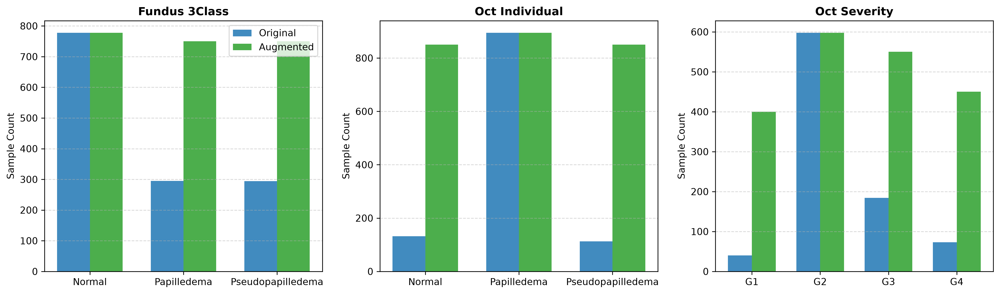

=== Side-by-Side Comparison: fundus_3class ===


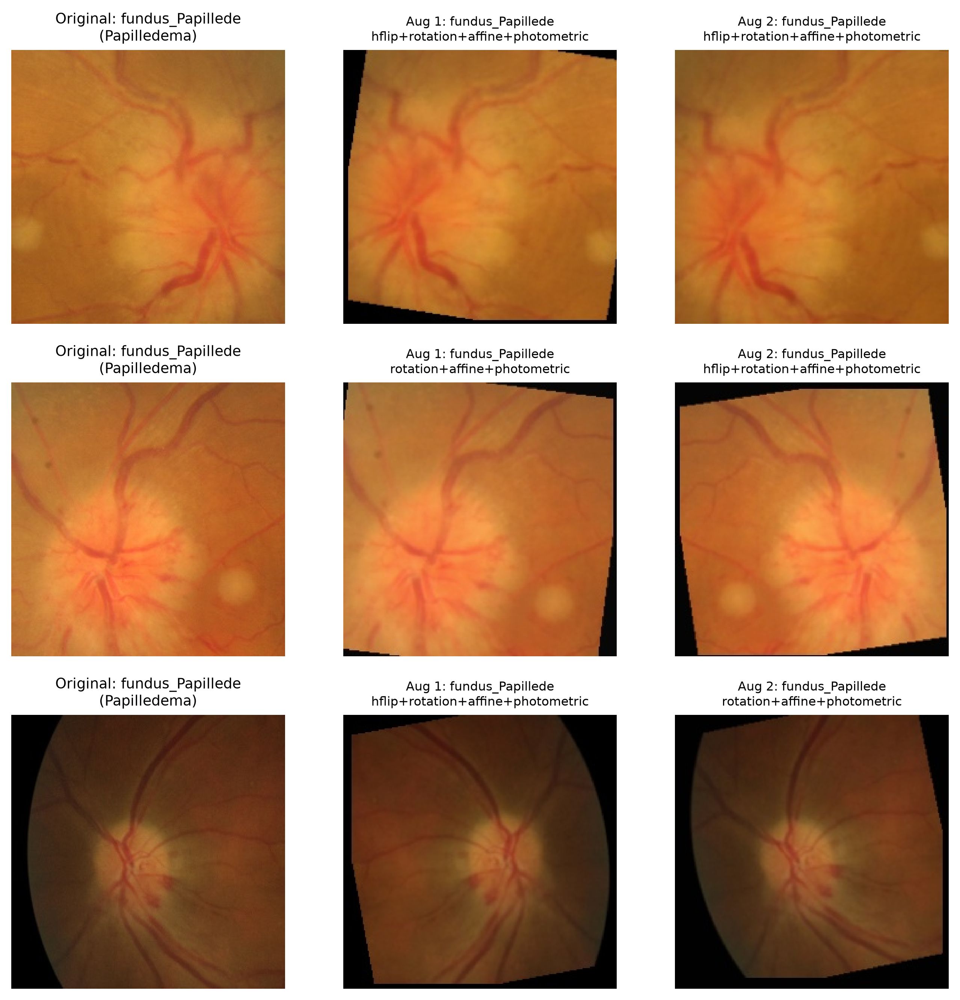

=== Side-by-Side Comparison: oct_individual ===


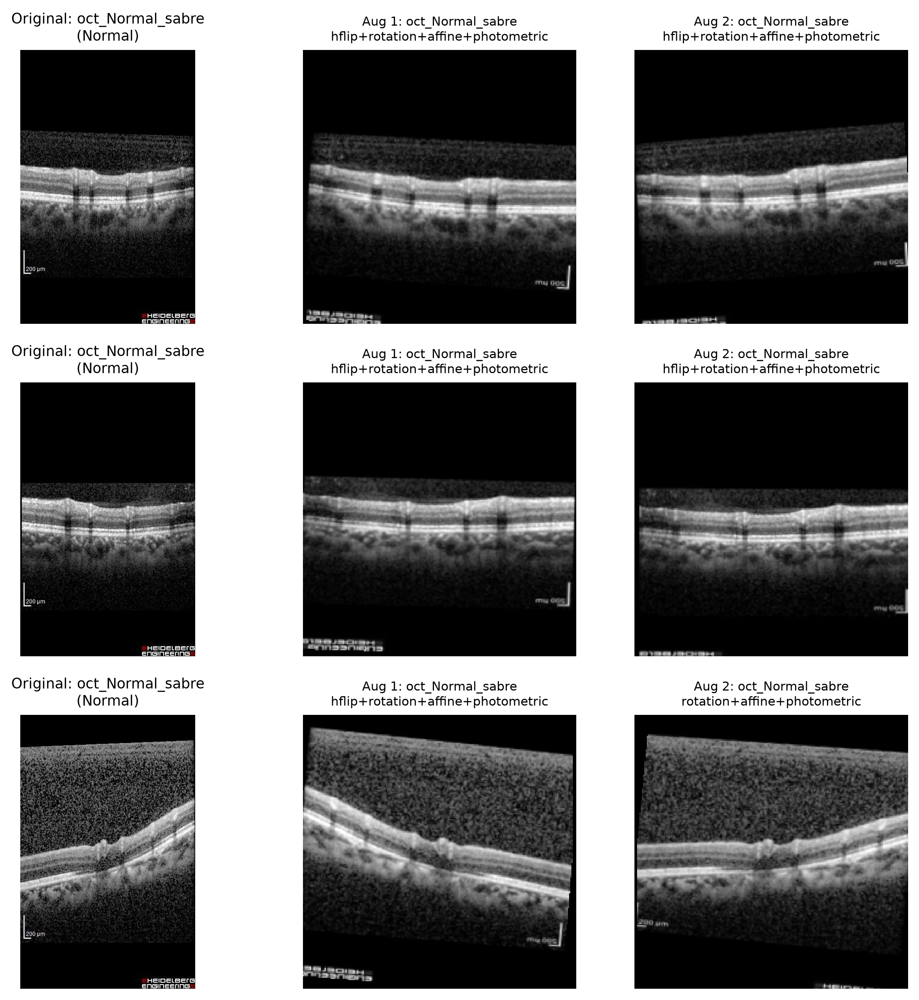

=== Side-by-Side Comparison: oct_severity ===


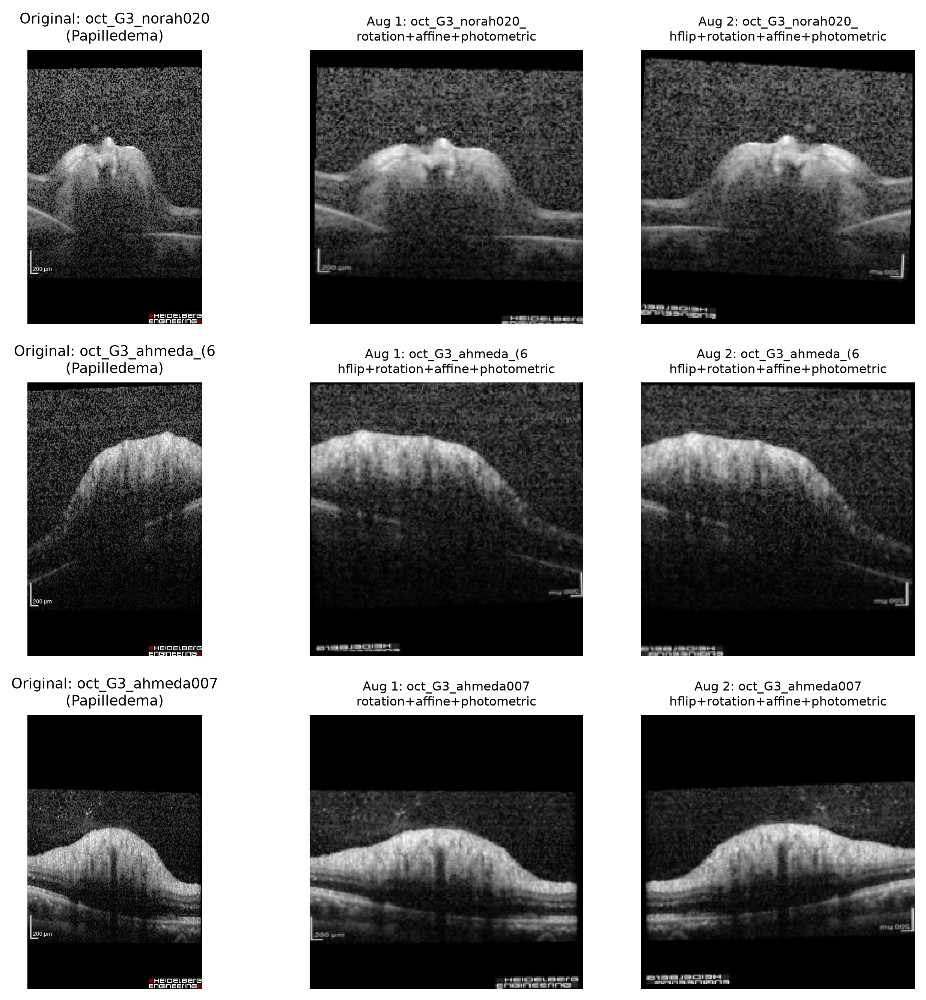

In [14]:
# Display augmentation distributions and side-by-side grids
from IPython.display import Image, display

dist_img = root / "results" / "augmentation" / "augmentation_summary" / "augmentation_class_distributions.png"
if dist_img.exists():
    display(Image(filename=str(dist_img)))

for trk in ["fundus_3class", "oct_individual", "oct_severity"]:
    s_img = root / "results" / "augmentation" / "augmentation_summary" / f"{trk}_side_by_side.png"
    if s_img.exists():
        print(f"=== Side-by-Side Comparison: {trk} ===")
        display(Image(filename=str(s_img)))


## 17. Zero-Leakage Guarantee & Provenance Verification

Every synthetic image is persisted with deterministic naming (`{parent_id}__aug_{idx:03d}.png`) and registered in `results/augmentation/manifests/augmentation_manifest.csv` with its exact parent image ID, source dataset, class label, and transformation parameters.

**Zero-Leakage Invariant**:
Synthetic images are admitted into a training fold IF AND ONLY IF their parent original image was assigned to that training fold (`original_image_id in train_df['sample_id']`). Validation and test folds remain 100% original and unaugmented.


In [15]:
man_p = root / "results" / "augmentation" / "manifests" / "augmentation_manifest.csv"
if man_p.exists():
    m_df = pd.read_csv(man_p)
    print(f"Total manifest entries: {len(m_df):,}")
    print(f"Original images retained: {len(m_df[~m_df['is_synthetic']]):,}")
    print(f"Synthetic images generated: {len(m_df[m_df['is_synthetic']]):,}")
    assert m_df[m_df["is_synthetic"]]["original_image_id"].notna().all()
    print("Zero-leakage verified: All synthetic images strictly link to valid original image IDs.")


Total manifest entries: 6,871
Original images retained: 3,402
Synthetic images generated: 3,469
Zero-leakage verified: All synthetic images strictly link to valid original image IDs.
